# D04-DB — DBSCAN trên RFM + AOV + Diversity (cap P99 + log1p + RobustScaler + PCA 90%)

Thí nghiệm **D04-DB** (người chạy: Nguyên) theo chiến lược model. So với D01, **chỉ thay StandardScaler bằng RobustScaler** (dùng trung vị và khoảng tứ phân vị 25–75): làm sạch → 5 feature → cap P99 (Frequency, Monetary, AOV, Diversity; giữ Recency) → `log1p` → **RobustScaler** → PCA giữ ≥ 90% phương sai → DBSCAN. Mục đích: đo phần tăng thêm của bộ chuẩn hóa robust ở nhánh D.

Lưới `eps × min_samples` (72 cấu hình) và quy tắc chọn giữ nguyên như D02-DB, E02-DB của Thuận và B01-DB của An: ≥ 2 cụm, nhiễu ≤ 5%, Silhouette (trên khách không nhiễu) cao nhất, hòa thì lấy nhiễu thấp hơn. D01-DB chưa có trong repo nên được dựng lại ngay trong notebook để so cùng điều kiện; kết quả dựng lại cũng được đối chiếu với E02-DB của Thuận.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
CAP_FEATURES = ["Frequency", "Monetary", "AOV", "Diversity"]   # cap các biến này; Recency giữ nguyên
CAP_Q = 99                          # P99, giống D01 và D04-KM của Thuận
PCA_VAR = 0.90                      # giữ ít nhất 90% phương sai (giống D01)
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]
EPS_GRID = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]   # 12 giá trị, giống D02-DB / E02-DB / B01-DB
RANDOM_STATE = 42
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..D02), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes (số mã hàng khác nhau của khách)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm. Cùng tệp đặc trưng 4.327 khách với các thí nghiệm A–D. Đuôi phải rất dài (Monetary lớn nhất 278.748 so với trung vị khoảng 658), là lý do nhánh D cắt đuôi ở cấp khách và thử bộ chuẩn hóa robust.

## Winsorization P99 (cap)

Giống hệt D01: ngưỡng cap = phân vị 99 của Frequency, Monetary, AOV và Diversity; Recency không cap; cap áp dụng trước `log1p`, trên giá trị gốc, không xóa khách nào.

In [3]:
caps = X.quantile(CAP_Q / 100)
caps[[c for c in FEATURES if c not in CAP_FEATURES]] = np.inf        # Recency giữ nguyên
capped = X.gt(caps, axis=1)
X_cap = X.clip(upper=caps, axis=1)

cap_report = pd.DataFrame({
    "cap": caps.replace(np.inf, np.nan).round(2),
    "customers_capped": capped.sum(),
    "customers_capped_pct": (100 * capped.mean()).round(2),
    "value_capped_pct": (100 * (X - X_cap).sum() / X.sum()).round(2),
})
n_capped = int(capped.any(axis=1).sum())
print(f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%) | số khách sau cap: {len(X_cap)} (không xóa khách nào)")
cap_report

Khách bị cap ở ít nhất 1 biến: 116 (2.68%) | số khách sau cap: 4327 (không xóa khách nào)


,cap,customers_capped,customers_capped_pct,value_capped_pct
Recency,NaN,0,0.00,0.00
Frequency,30.00,42,0.97,6.12
Monetary,17279.06,44,1.02,21.62
AOV,1894.54,44,1.02,4.45
Diversity,353.74,44,1.02,3.50


**Nhận xét:** Ngưỡng P99 là Frequency 30, Monetary 17.279, AOV 1.895, Diversity 354; **116 khách (2,68%)** bị cap, phần giá trị bị cắt là 21,62% tổng Monetary (6,12% Frequency, 4,45% AOV, 3,50% Diversity). Giống hệt D01 và D04-KM của Thuận.

## RobustScaler và PCA giữ 90% phương sai

RobustScaler trừ trung vị và chia cho khoảng tứ phân vị (25–75) thay vì chia cho độ lệch chuẩn. Dựng cả không gian Standard (cho D01) để so.

In [4]:
def make_prep(caps_values, scaler, n_components=None):
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", scaler)]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components, svd_solver="full", random_state=RANDOM_STATE)))
    return Pipeline(steps)

def build_space(caps_values, scaler_factory):
    Xs = make_prep(caps_values, scaler_factory()).fit_transform(X.values)
    ev = PCA(svd_solver="full").fit(Xs).explained_variance_ratio_
    cum = np.cumsum(ev)
    n = int(np.searchsorted(cum, PCA_VAR) + 1)
    pre = make_prep(caps_values, scaler_factory(), n).fit(X.values)
    return pre, pre.transform(X.values), ev, cum, n

caps_values = caps.to_numpy()
robust = lambda: RobustScaler(quantile_range=(25.0, 75.0))
prep, Z, ev, cum, n_pc = build_space(caps_values, robust)
_, Z_d01, _, cum_d01, n_d01 = build_space(caps_values, StandardScaler)       # không gian D01 (Standard)

print("D04 (Robust)   — phương sai từng PC:", ev.round(4), "| số PC:", n_pc, f"| phương sai giữ lại {cum[n_pc-1]:.2%}")
print("D01 (Standard) — số PC:", n_d01, f"| phương sai giữ lại {cum_d01[n_d01-1]:.2%}")
pd.DataFrame(prep["pca"].components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

D04 (Robust)   — phương sai từng PC: [0.6226 0.2163 0.0897 0.0702 0.0011] | số PC: 3 | phương sai giữ lại 92.87%
D01 (Standard) — số PC: 3 | phương sai giữ lại 92.41%


,Recency,Frequency,Monetary,AOV,Diversity
PC1,-0.300,0.366,0.562,0.470,0.489
PC2,0.487,-0.413,0.034,0.753,-0.154
PC3,0.712,0.114,-0.028,-0.266,0.639


**Nhận xét:** Cả hai bộ chuẩn hóa đều cần **3 PC** trên 5 biến để vượt 90%; RobustScaler giữ 92,87% (Standard: 92,41%), nên PCA thực sự giảm chiều như ở C01 và D01.

## Chọn eps bằng đồ thị k-distance và kiểm tra thang eps

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó), sắp xếp tăng dần. RobustScaler đổi thang khoảng cách so với Standard, nên đo xem lưới eps gốc có còn phủ vùng cần quét hay không (ở B04 với MinMax, lưới gốc không còn phủ và phải quy đổi).

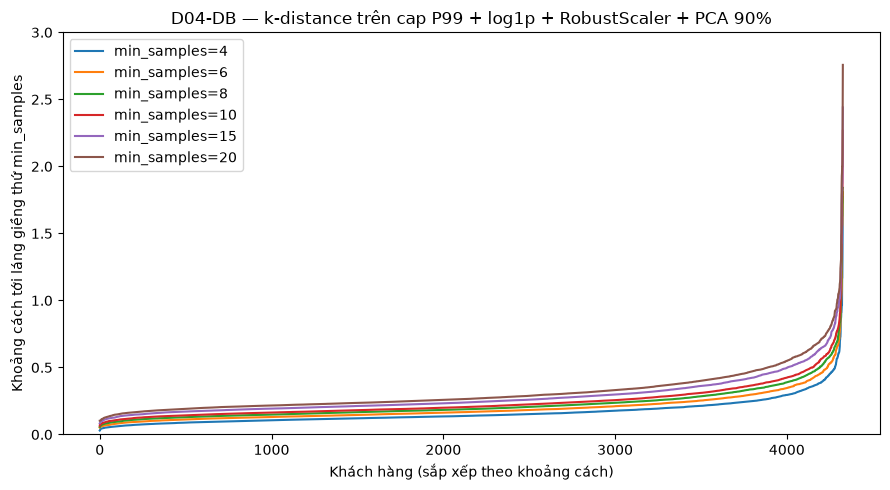

Hệ số thang (Robust / Standard) = trung vị tỷ số P99 của k-distance = 0.743

k-distance Robust:
        4      6      8      10     15     20
P50  0.140  0.169  0.190  0.206  0.240  0.267
P90  0.266  0.318  0.357  0.390  0.456  0.502
P95  0.338  0.389  0.439  0.478  0.554  0.615
P99  0.516  0.595  0.663  0.722  0.847  0.926

k-distance Standard (D01):
        4      6      8      10     15     20
P50  0.195  0.238  0.266  0.291  0.338  0.376
P90  0.372  0.441  0.489  0.526  0.609  0.671
P95  0.458  0.541  0.601  0.657  0.753  0.836
P99  0.697  0.804  0.868  0.968  1.143  1.235


In [5]:
def kdist(Zs):
    d = {ms: np.sort(NearestNeighbors(n_neighbors=ms).fit(Zs).kneighbors(Zs)[0][:, -1]) for ms in MIN_SAMPLES_GRID}
    q = pd.DataFrame({ms: np.quantile(v, [0.5, 0.9, 0.95, 0.99]) for ms, v in d.items()}, index=["P50", "P90", "P95", "P99"])
    return d, q

kd, q_rob = kdist(Z)
_, q_std = kdist(Z_d01)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kd.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 3)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("D04-DB — k-distance trên cap P99 + log1p + RobustScaler + PCA 90%")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

scale = float(np.median([q_rob.loc["P99", ms] / q_std.loc["P99", ms] for ms in MIN_SAMPLES_GRID]))
print(f"Hệ số thang (Robust / Standard) = trung vị tỷ số P99 của k-distance = {scale:.3f}")
print("\nk-distance Robust:"); print(q_rob.round(3).to_string())
print("\nk-distance Standard (D01):"); print(q_std.round(3).to_string())

**Nhận xét:** Khoảng cách trong không gian Robust chỉ nhỏ hơn Standard khoảng 26% (hệ số ≈ 0,74; P99 của k-distance từ 0,52 đến 0,93 so với 0,70 đến 1,24 ở Standard), nên **lưới eps gốc (0,05–2,0) vẫn phủ từ P50 (0,14–0,27) tới trên P99**. Vì vậy D04 dùng nguyên lưới gốc để giữ nguyên giao thức và so được với D02-DB, E02-DB; phép quy đổi eps theo hệ số 0,74 được chạy bên dưới như kiểm tra độ nhạy.

## Quét lưới eps × min_samples (D04)

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [6]:
def run_dbscan(Zs, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zs)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Zs), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = silhouette_score(Zs[mask], labels[mask])
        row["dbi"] = davies_bouldin_score(Zs[mask], labels[mask])
    return row, labels

def run_grid(Zs, eps_grid):
    pairs = [(e, m) for m in MIN_SAMPLES_GRID for e in eps_grid]
    out = [run_dbscan(Zs, e, m) for e, m in pairs]
    return pd.DataFrame([r for r, _ in out]), {p: l for p, (_, l) in zip(pairs, out)}

def select(g):
    # ≥ 2 cụm, nhiễu ≤ 5%, Silhouette cao nhất; hòa thì lấy nhiễu thấp hơn (giống D02-DB của Thuận)
    valid = g[(g["n_clusters"] >= MIN_CLUSTERS) & (g["noise_pct"] <= MAX_NOISE * 100)]
    return valid.sort_values(["silhouette", "noise_pct"], ascending=[False, True]).iloc[0], valid

grid, lab_d04 = run_grid(Z, EPS_GRID)
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()), "| chỉ 1 cụm:", int((grid["n_clusters"] == 1).sum()))
print("Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách:", int(((grid["n_clusters"] >= 2) & (grid["largest_pct"] < 90)).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(8).round(4)

Số cấu hình đã chạy: 72
Số cấu hình có >= 2 cụm: 28 | chỉ 1 cụm: 38
Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách: 23


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
0,4,0.05,12,98.71,0.21,3,0.6653,0.3945
49,15,0.10,3,98.31,0.99,15,0.5930,0.4750
37,10,0.10,6,96.26,1.59,12,0.5463,0.5468
25,8,0.10,12,93.39,2.36,6,0.4834,0.5016
62,20,0.15,6,92.88,3.00,21,0.4719,0.6025
6,4,0.40,2,1.29,98.52,8,0.4469,0.4701
13,6,0.10,38,86.69,2.91,4,0.3828,0.5862
52,15,0.25,4,29.37,69.15,12,0.2761,0.7020


**Nhận xét:** 28/72 cấu hình có ≥ 2 cụm (Standard ở D01: 35/72). Các cấu hình có Silhouette cao nhất đều **gán rất nhiều khách vào nhiễu** (ví dụ min_samples = 4, eps = 0,05: 12 cụm nhưng 98,71% khách là nhiễu, Silhouette 0,6653), nên không dùng được; 23 cấu hình chia khối chính đều hơn (cụm lớn nhất < 90%) cũng đều bị loại vì nhiễu > 5% hoặc không đạt điều kiện.

## Chọn cấu hình

Cùng quy tắc của nhánh D (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, **Silhouette cao nhất**, hòa thì lấy nhiễu thấp hơn.

In [7]:
best, valid = select(grid)
print(f"Số cấu hình đạt điều kiện (>= 2 cụm, nhiễu <= 5%): {len(valid)}")
print("Cấu hình được chọn:")
print(best.round(4).to_string())
print()
valid.round(4)

Số cấu hình đạt điều kiện (>= 2 cụm, nhiễu <= 5%): 2
Cấu hình được chọn:
min_samples     4.0000
eps             0.4000
n_clusters      2.0000
noise_pct       1.2900
largest_pct    98.5200
smallest        8.0000
silhouette      0.4469
dbi             0.4701



,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
5,4,0.3,6,4.25,94.82,4,-0.1354,0.7662
6,4,0.4,2,1.29,98.52,8,0.4469,0.4701


**Nhận xét:** Chỉ **2 cấu hình** đạt điều kiện. Cấu hình được chọn là `min_samples = 4`, `eps = 0,4`: 2 cụm, nhiễu 1,29% (56 khách), cụm lớn nhất 98,52% (4.263 khách), cụm còn lại chỉ 8 khách; Silhouette 0,4469, DBI 0,4701. Cấu hình còn lại (`min_samples = 4`, `eps = 0,3`: 6 cụm, nhiễu 4,25%) có Silhouette âm (−0,1354). Vì chỉ một cấu hình dương nên lựa chọn này gần như là duy nhất; Silhouette cao vì một khối 98,5% khách nằm cách xa 8 khách ngoại lai, không phải vì phân khúc tốt.

## Hồ sơ cụm

Nhãn `-1` là nhiễu. Mô tả bằng trung vị **trên thang gốc, trước khi cap**. Cột `Monetary_share_pct` là tỷ trọng tổng Monetary gốc của nhóm.

In [8]:
labels = lab_d04[(float(best["eps"]), int(best["min_samples"]))]
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"), Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")

prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
-1,56,11.5,3.0,1230.5,718.8,9.0,1.3,12.2
0,4263,52.0,2.0,656.6,285.5,36.0,98.5,79.1
1,8,9.5,24.0,78858.0,3035.2,448.0,0.2,8.6


**Nhận xét:**
- **Cụm 0 (4.263 khách, 98,5%)** có hồ sơ gần trung vị toàn bộ khách (Recency 52, Frequency 2, Monetary ≈ 657, AOV ≈ 286, Diversity 36) và đóng góp 79,1% Monetary.
- **Cụm 1 (8 khách, 0,2%)**: Recency 9,5, Frequency 24, Monetary ≈ 78.858, AOV ≈ 3.035, Diversity 448 → **nhóm khách cực lớn: mua rất thường xuyên, giá trị đơn và số mã hàng đều rất cao**; chiếm 8,6% tổng Monetary.
- **56 khách nhiễu (1,3%)**: Recency 11,5, Frequency 3, Monetary ≈ 1.231, AOV ≈ 719 nhưng Diversity chỉ 9 → **khách mua đơn giá trị cao với rất ít chủng loại hàng**; chiếm 12,2% Monetary.

Tức là DBSCAN chỉ tách phần đuôi ngoại lai (8 khách cực lớn và 56 khách đơn lớn ít chủng loại), không chia khối chính thành phân khúc.

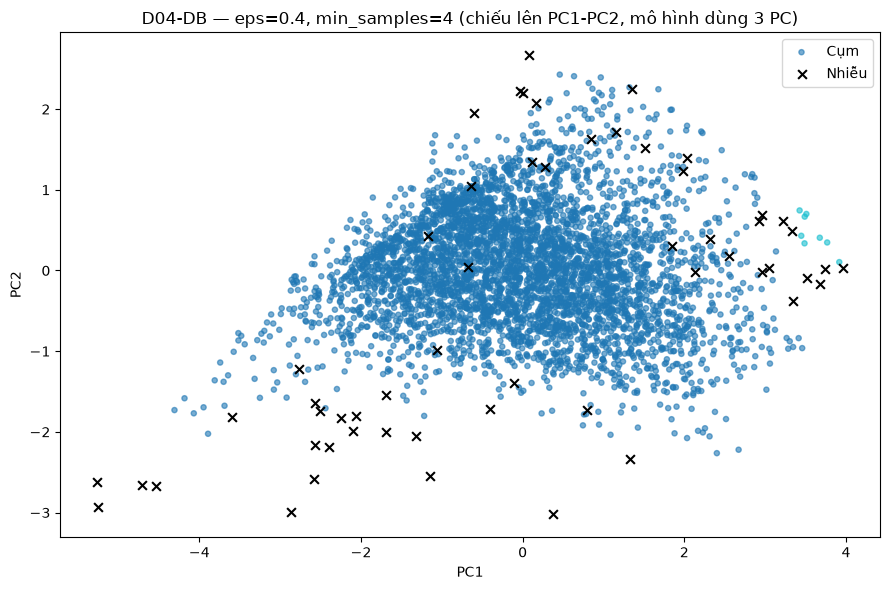

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=40, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"D04-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (chiếu lên PC1-PC2, mô hình dùng {n_pc} PC)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Toàn bộ khách dồn thành một khối liền; 8 khách của cụm 1 và các điểm nhiễu nằm rải ở phần đuôi xa. Hình xác nhận DBSCAN chỉ bắt phần đuôi ngoại lai.

## Đối chiếu D01 (dựng lại) và kiểm tra độ nhạy thang eps

Ba việc: (1) dựng lại D01-DB (cap P99 + Standard, cùng lưới và quy tắc) và đối chiếu với E02-DB của Thuận, vốn cùng tập feature và cùng cap P99; (2) so cấu hình được chọn và từng ô lưới giữa D04 (Robust) và D01 (Standard); (3) chạy lại D04 với lưới eps nhân hệ số thang để xem kết luận có đổi không. ARI đo mức trùng nhóm (nhãn nhiễu −1 được tính như một nhóm), 1,0 là giống hệt.

In [10]:
# (1) D01-DB dựng lại và đối chiếu E02-DB của Thuận
grid_d01, lab_d01 = run_grid(Z_d01, EPS_GRID)
best_d01, valid_d01 = select(grid_d01)
labels_d01 = lab_d01[(float(best_d01["eps"]), int(best_d01["min_samples"]))]
print(f"D01-DB (Standard): {int((grid_d01['n_clusters'] >= 2).sum())}/{len(grid_d01)} cấu hình có >= 2 cụm | {len(valid_d01)} cấu hình đạt điều kiện")
e02 = json.load(open(find("notebooks/03_clustering_eval/19-11-2026-thuan-dbscan-e02/data/dbscan_e02_params.json"), encoding="utf8"))
print(f"D01-DB dựng lại: eps={best_d01['eps']}, min_samples={int(best_d01['min_samples'])}, {int(best_d01['n_clusters'])} cụm, "
      f"nhiễu {best_d01['noise_pct']}%, Silhouette={best_d01['silhouette']:.4f}, DBI={best_d01['dbi']:.4f}")
print(f"E02-DB của Thuận: eps={e02['eps']}, min_samples={e02['min_samples']}, {e02['n_clusters']} cụm, "
      f"nhiễu {e02['noise_pct']}%, Silhouette={e02['silhouette_non_noise']:.4f}, DBI={e02['dbi_non_noise']:.4f}, loại biến: {e02['dropped_features']}")
same_e02 = (e02["eps"] == float(best_d01["eps"]) and e02["min_samples"] == int(best_d01["min_samples"])
            and e02["n_clusters"] == int(best_d01["n_clusters"]) and abs(e02["silhouette_non_noise"] - best_d01["silhouette"]) < 1e-4)
print("Trùng hoàn toàn:", same_e02)

# (2) D04 so với D01
ari_sel = adjusted_rand_score(labels, labels_d01)
matched = [adjusted_rand_score(lab_d04[(e, m)], lab_d01[(e, m)]) for m in MIN_SAMPLES_GRID for e in EPS_GRID]
n_ident, med_ari, min_ari = sum(a == 1.0 for a in matched), float(np.median(matched)), float(min(matched))
print(f"\nARI giữa hai cấu hình được chọn: {ari_sel:.4f}")
print(f"ARI theo từng ô lưới (cùng eps, cùng min_samples): giống hệt {n_ident}/{len(matched)} ô | trung vị {med_ari:.4f} | nhỏ nhất {min_ari:.4f}")

# (3) Độ nhạy: lưới eps nhân hệ số thang
EPS_SCALED = [round(e * scale, 4) for e in EPS_GRID]
grid_sc, lab_sc = run_grid(Z, EPS_SCALED)
best_sc, valid_sc = select(grid_sc)
labels_sc = lab_sc[(float(best_sc["eps"]), int(best_sc["min_samples"]))]
matched_sc = [adjusted_rand_score(lab_sc[(es, m)], lab_d01[(e, m)]) for m in MIN_SAMPLES_GRID for e, es in zip(EPS_GRID, EPS_SCALED)]
print(f"\nLưới eps × {scale:.3f}: {len(valid_sc)} cấu hình đạt điều kiện | chọn eps={best_sc['eps']}, min_samples={int(best_sc['min_samples'])}: "
      f"{int(best_sc['n_clusters'])} cụm, nhiễu {best_sc['noise_pct']}% ({int((labels_sc == -1).sum())} khách), cụm nhỏ nhất {int(best_sc['smallest'])}, "
      f"Silhouette={best_sc['silhouette']:.4f}")
print(f"ARI giữa cấu hình chọn của lưới gốc và lưới quy đổi: {adjusted_rand_score(labels, labels_sc):.4f}")
print(f"ARI D04 (lưới quy đổi) và D01 theo ô tương ứng: giống hệt {sum(a == 1.0 for a in matched_sc)}/{len(matched_sc)} ô | trung vị {np.median(matched_sc):.4f}")

D01-DB (Standard): 35/72 cấu hình có >= 2 cụm | 3 cấu hình đạt điều kiện
D01-DB dựng lại: eps=0.5, min_samples=6, 3 cụm, nhiễu 3.42%, Silhouette=0.1351, DBI=0.5919
E02-DB của Thuận: eps=0.5, min_samples=6, 3 cụm, nhiễu 3.42%, Silhouette=0.1351, DBI=0.5919, loại biến: []
Trùng hoàn toàn: True

ARI giữa hai cấu hình được chọn: 0.4881
ARI theo từng ô lưới (cùng eps, cùng min_samples): giống hệt 6/72 ô | trung vị 0.3526 | nhỏ nhất -0.0890

Lưới eps × 0.743: 4 cấu hình đạt điều kiện | chọn eps=0.5203, min_samples=8: 2 cụm, nhiễu 0.97% (42 khách), cụm nhỏ nhất 8, Silhouette=0.4519
ARI giữa cấu hình chọn của lưới gốc và lưới quy đổi: 0.8548
ARI D04 (lưới quy đổi) và D01 theo ô tương ứng: giống hệt 13/72 ô | trung vị 0.6851


In [11]:
def line(name, scaler, n_components, g_row, lab, note):
    sizes = pd.Series(lab[lab != -1]).value_counts().tolist()
    return {"Thí nghiệm": name, "Scaler": scaler, "Số PC": n_components, "Lưới eps": note,
            "eps": float(g_row["eps"]), "min_samples": int(g_row["min_samples"]), "Số cụm": int(g_row["n_clusters"]),
            "Nhiễu (khách)": int((lab == -1).sum()), "Nhiễu (%)": float(g_row["noise_pct"]),
            "Cụm lớn nhất (%)": float(g_row["largest_pct"]), "Silhouette": float(g_row["silhouette"]),
            "DBI": float(g_row["dbi"]), "Kích thước cụm": sizes}

cmp = pd.DataFrame([
    line("D04-DB", "log1p + Robust", n_pc, best, labels, "lưới gốc (72)"),
    line("D01-DB (dựng lại)", "log1p + Standard", n_d01, best_d01, labels_d01, "lưới gốc (72)"),
    line("D04-DB (kiểm tra độ nhạy)", "log1p + Robust", n_pc, best_sc, labels_sc, f"lưới gốc × {scale:.3f}"),
])
print("Hồ sơ cụm D01-DB dựng lại:"); print(profile(labels_d01).round(1).to_string())
cmp

Hồ sơ cụm D01-DB dựng lại:
         customers  Recency  Frequency  Monetary     AOV  Diversity  customer_share_pct  Monetary_share_pct
cluster                                                                                                    
-1             148     19.0        4.0    1167.0   241.9       35.5                 3.4                24.9
 0            4172     52.0        2.0     656.0   286.9       35.0                96.4                75.0
 1               3     67.0        2.0    4279.7  3914.9      114.0                 0.1                 0.2
 2               4     33.5        1.0      39.4    39.4        2.0                 0.1                 0.0


,Thí nghiệm,Scaler,Số PC,Lưới eps,eps,min_samples,Số cụm,Nhiễu (khách),Nhiễu (%),Cụm lớn nhất (%),Silhouette,DBI,Kích thước cụm
0,D04-DB,log1p + Robust,3,lưới gốc (72),0.4000,4,2,56,1.29,98.52,0.446917,0.470115,"[4263, 8]"
1,D01-DB (dựng lại),log1p + Standard,3,lưới gốc (72),0.5000,6,3,148,3.42,96.42,0.135094,0.591924,"[4172, 4, 3]"
2,D04-DB (kiểm tra độ nhạy),log1p + Robust,3,lưới gốc × 0.743,0.5203,8,2,42,0.97,98.84,0.451936,0.462748,"[4277, 8]"


**Nhận xét:**
- **Dựng lại D01-DB khớp E02-DB của Thuận** (eps 0,5, min_samples 6, 3 cụm, nhiễu 3,42%, Silhouette 0,1351, DBI 0,5919): E02 dùng cap P99 và lọc tương quan 0,85 nhưng không loại biến nào, nên cùng tập feature với D01. Vì vậy **D01-DB tương đương E02-DB** (và theo cùng lý do E01-DB, E03-DB cũng tương đương D01-DB).
- **RobustScaler đổi cách DBSCAN tách ngoại lai nhưng không đổi bức tranh:** cả hai đều chỉ tách đuôi ngoại lai khỏi khối 96–98% khách. D01-DB (Standard) chọn 3 cụm (4.172 / 3 / 4 khách) kèm 148 khách nhiễu (3,42%), Silhouette 0,1351; D04-DB (Robust) chọn 2 cụm (4.263 / 8 khách) kèm 56 khách nhiễu (1,29%), Silhouette 0,4469. Silhouette cao hơn ở D04 chỉ vì cụm phụ nhỏ và cách xa, không phản ánh phân khúc tốt hơn.
- **Hai cách chia khác nhau vừa phải:** ARI giữa hai cấu hình được chọn là 0,4881; theo từng ô lưới (cùng eps, cùng min_samples) chỉ 6/72 ô giống hệt và ARI trung vị 0,3526, một phần vì cùng một eps ứng với thang khác nhau giữa hai bộ chuẩn hóa. Khi quy đổi eps của D04 theo thang (nhân 0,74), số ô giống hệt tăng lên 13/72 và ARI trung vị lên 0,6851: một phần khác biệt là do thang eps, phần còn lại do RobustScaler thật sự đổi hình dạng không gian.
- **Kết luận chịu được thay đổi thang eps:** lưới quy đổi theo hệ số 0,74 cũng chọn 2 cụm với cụm phụ 8 khách (nhiễu 0,97%, Silhouette 0,4519; ARI 0,8548 so với lựa chọn của lưới gốc); không có cấu hình chia khối chính thành phân khúc cân đối đạt điều kiện nhiễu ở cả hai lưới.

## Lưu kết quả

In [12]:
grid.to_csv(OUT / "dbscan_d04_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_d04_labels.csv", index=False)
params = {"experiment": "D04-DB", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()}, "customers_capped": n_capped,
          "transform": "log1p", "scaler": "RobustScaler(quantile_range=(25, 75))",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]), "eps_scale_vs_standard": round(scale, 4),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "configs_passing_rule": int(len(valid)), "ari_vs_d01_selected": round(float(ari_sel), 4),
          "equivalent_note": "D01-DB dựng lại trùng E02-DB (Thuận); E01-DB, E03-DB tương đương D01-DB"}
json.dump(params, open(OUT / "dbscan_d04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_d04_grid.csv', 'dbscan_d04_labels.csv', 'dbscan_d04_params.json']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng cấu hình, bảng cụm), chuyển các cột cho DBSCAN, thêm bảng đối chiếu D01 và sheet `Cap`.

In [13]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "DBSCAN_D04"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None, sheet=None):
    sh = sheet or ws
    sh[cell] = value
    sh[cell].font = B if bold else Font(name="Calibri")
    if fmt: sh[cell].number_format = fmt

e_best, m_best = float(best["eps"]), int(best["min_samples"])
put("A1", "THÍ NGHIỆM DBSCAN — D04 (RFM + AOV + Diversity, cap P99, log1p, RobustScaler, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; Silhouette/DBI tính trên khách không bị gán nhiễu, trong không gian đã fit")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity"),
        ("Dữ liệu train", f"Z (cap P99 → log1p → Robust(25–75) → PCA 90%, {n_pc} PC)"),
        ("eps được chọn", e_best), ("min_samples được chọn", m_best),
        ("Quy tắc chọn", "≥ 2 cụm, nhiễu ≤ 5%, Silhouette lớn nhất (hòa: nhiễu thấp hơn)"),
        ("Lưới", f"{len(EPS_GRID)} eps × {len(MIN_SAMPLES_GRID)} min_samples = {len(grid)}")]
right = [("PCA", f"90% → {n_pc}/{len(FEATURES)} PC (phương sai {cum[n_pc-1]:.2%})"), ("Tổng khách hàng", int(len(X))),
         ("Số cụm (không tính nhiễu)", int(best["n_clusters"])), ("Nhiễu (%)", float(best["noise_pct"])),
         ("Winsorization", f"P{CAP_Q}: {n_capped} khách ({100*n_capped/len(X):.2f}%) bị cap"),
         ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)

hdr = ["min_samples", "eps", "Số cụm", "Nhiễu (%)", "Cụm lớn nhất (%)", "Cụm nhỏ nhất (khách)", "Silhouette", "DBI", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(f"{c}12", v, bold=True)
multi = grid[grid["n_clusters"] >= 2].sort_values(["silhouette", "noise_pct"], ascending=[False, True])
for i, r in enumerate(multi.itertuples(), start=13):
    if r.eps == e_best and r.min_samples == m_best: note = "cấu hình được chọn"
    elif r.noise_pct > MAX_NOISE * 100: note = "loại: nhiễu > 5%"
    else: note = "đạt điều kiện nhiễu"
    if r.silhouette < 0: note = (note + "; " if note else "") + "Silhouette âm"
    vals = [int(r.min_samples), float(r.eps), int(r.n_clusters), float(r.noise_pct), float(r.largest_pct),
            int(r.smallest), float(r.silhouette), float(r.dbi), note]
    fmts = [None, "0.00", None, "0.00", "0.00", None, "0.0000", "0.0000", None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(f"{c}{i}", v, fmt=f)
put(f"A{13 + len(multi)}", f"Chỉ liệt kê {len(multi)}/{len(grid)} cấu hình có ≥ 2 cụm; các cấu hình còn lại chỉ có 1 cụm.")

r0 = 13 + len(multi) + 3
hdr2 = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)", "Monetary (median)",
        "AOV (median)", "Diversity (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGHIJ", hdr2): put(f"{c}{r0}", v, bold=True)
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    nhom = ("Nhiễu (ngoại lai)" if cl == -1 else "Khối chính" if p["customers"] == prof["customers"].max() else "Cụm nhỏ")
    vals = [int(cl), nhom, int(p["customers"]), float(p["customer_share_pct"]), float(p["Recency"]), float(p["Frequency"]),
            float(p["Monetary"]), float(p["AOV"]), float(p["Diversity"]), float(p["Monetary_share_pct"])]
    fmts = [None, None, None, "0.00", None, None, "0.00", "0.00", None, "0.00"]
    for c, v, f in zip("ABCDEFGHIJ", vals, fmts): put(f"{c}{j}", v, fmt=f)

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu D01-DB (dựng lại) và kiểm tra độ nhạy thang eps", bold=True)
for c, v in zip("ABCDEFGHIJ", ["Thí nghiệm", "Scaler", "Lưới eps", "eps", "min_samples", "Số cụm", "Nhiễu (khách)", "Nhiễu (%)", "Silhouette", "DBI"]):
    put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], r[1], r[3], r[4], r[5], r[6], r[7], r[8], r[10], r[11]]
    for c, v, f in zip("ABCDEFGHIJ", vals, [None, None, None, "0.0000", None, None, None, "0.00", "0.0000", "0.0000"]):
        put(f"{c}{j}", v, fmt=f)
nb_ = r1 + 2 + len(cmp) + 1
put(f"A{nb_}", f"ARI giữa hai cấu hình được chọn (D04 so với D01): {ari_sel:.4f}")
put(f"A{nb_+1}", f"Theo từng ô lưới (cùng eps, cùng min_samples): giống hệt {n_ident}/{len(matched)} ô; ARI trung vị {med_ari:.3f}")
put(f"A{nb_+2}", f"D01-DB dựng lại trùng E02-DB (Thuận): {same_e02} (cap P99, không loại biến nào) nên E01-DB, E03-DB tương đương D01-DB.")
put(f"A{nb_+3}", f"Hệ số thang Robust/Standard (trung vị tỷ số P99 k-distance): {scale:.3f}; lưới quy đổi chọn cụm phụ {int(best_sc['smallest'])} khách, Silhouette {best_sc['silhouette']:.4f}.")
put(f"A{nb_+4}", "Silhouette/DBI của các thí nghiệm tính trên các không gian khác nhau và đều do tách vài khách ngoại lai, không so trực tiếp.")
for col, w in zip("ABCDEFGHIJ", [16, 22, 17, 19, 20, 21, 25, 22, 18, 22]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws3 = wb.create_sheet("Cap")
for c, v in zip("ABCDE", ["Biến", f"Ngưỡng cap (P{CAP_Q})", "Số khách bị cap", "Tỷ lệ khách bị cap (%)", "Giá trị bị cắt (% tổng)"]):
    put(f"{c}1", v, bold=True, sheet=ws3)
for i, (feat, r) in enumerate(cap_report.iterrows(), start=2):
    put(f"A{i}", feat, sheet=ws3)
    put(f"B{i}", "không cap" if np.isnan(r["cap"]) else float(r["cap"]), fmt="0.00", sheet=ws3)
    put(f"C{i}", int(r["customers_capped"]), sheet=ws3); put(f"D{i}", float(r["customers_capped_pct"]), fmt="0.00", sheet=ws3)
    put(f"E{i}", float(r["value_capped_pct"]), fmt="0.00", sheet=ws3)
put(f"A{len(cap_report) + 3}", f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%); không xóa khách nào ({len(X)} khách còn nguyên).", sheet=ws3)
for col, w in zip("ABCDE", [14, 20, 18, 24, 24]): ws3.column_dimensions[col].width = w

wb.save("Working_details_DBSCAN_D04.xlsx")
print("Đã lưu Working_details_DBSCAN_D04.xlsx")

Đã lưu Working_details_DBSCAN_D04.xlsx


## Kết luận D04-DB

- **DBSCAN vẫn chỉ tách ngoại lai:** cấu hình được chọn (`eps = 0,4`, `min_samples = 4`) cho 2 cụm: một khối 4.263 khách (98,5%) và cụm phụ 8 khách cực lớn (Frequency 24, Monetary ≈ 78.858), kèm 56 khách nhiễu (1,3%) mua đơn giá trị cao với rất ít chủng loại hàng (Diversity 9). Không có phân khúc cân đối.
- **RobustScaler đổi chi tiết, không đổi bức tranh:** so với D01-DB (Standard: 3 cụm 4.172 / 3 / 4 khách và 148 khách nhiễu), ARI giữa hai cấu hình được chọn là 0,4881 và chỉ 6/72 ô lưới giống hệt nhau; nhưng cả hai đều chỉ tách đuôi ngoại lai khỏi khối 96–98% khách. Silhouette cao hơn của D04 (0,4469 so với 0,1351) chỉ vì cụm phụ nhỏ và xa.
- **Chỉ 2 cấu hình đạt điều kiện** và một trong hai có Silhouette âm, nên lựa chọn gần như duy nhất; kết luận không đổi khi quy đổi eps theo thang Robust (cụm phụ vẫn 8 khách, Silhouette 0,4519).
- **D01-DB dựng lại trùng E02-DB của Thuận**, nên E01-DB, E02-DB, E03-DB đều tương đương D01-DB (không loại biến nào): nhánh E chỉ còn cần chạy thật E04.
- **Giới hạn:** Silhouette cao nhất đều thuộc cấu hình gán gần hết khách vào nhiễu và bị loại; muốn dùng DBSCAN để phân khúc cần tiêu chí chọn khác Silhouette.
- **Bước kế tiếp:** E04-DB (cap P99, bỏ PCA).